# Ensemble learning: separate, reproducible experiments

The custom estimator is imported from majority_vote.py so offline tests exercise
the exact code used here. Hard ties select the smallest encoded class; soft votes
align probability columns before averaging. Constructor parameters remain
cloneable and nested parameters support GridSearchCV.

Experiments: (1) full Iris first-two-feature illustration (70/30); (2) binary Iris
versicolor/virginica with sepal width and petal length (70/30, ROC-AUC); (3) binary
Wine classes 2/3 with alcohol and OD280/OD315 (80/20, accuracy); (4) full Iris with
all four features (70/30, accuracy). Every stratified split uses seed 1. Binary
and full Iris comparisons share their respective ten training folds; Wine uses
five. Scaling is inside LR/KNN pipelines in every fold. No test partition is used
for tuning. Wine boosting curves use an inner training-side validation split.

Wine comes from sklearn's packaged UCI copy, so all cells run without downloads.
The first full-data boundary plot is exploratory, not a held-out evaluation.
Grid sizes and estimator counts are retained; jobs are bounded to one for local
portability. Removed a post-selection CV re-run that was not independent evidence.


Full Iris first-2-features held-out accuracy (seed 1, 70/30): 0.7333333333333333


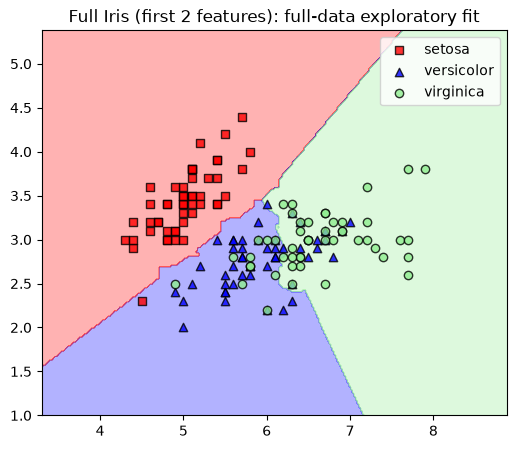

In [1]:
#PART 1: Implementing a Majority Vote Classifier
#Step 1.2: Implement Majority Voting Classifier
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from majority_vote import MajorityVoteClassifier

# Load Iris dataset
iris = load_iris()
X, y = iris.data[:, :2], iris.target   # use first 2 features for visualization
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

# Define classifiers
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
clf1 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=1))
clf2 = DecisionTreeClassifier(max_depth=3, random_state=1)
clf3 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

# Majority Vote
mv_clf = MajorityVoteClassifier(classifiers=[clf1, clf2, clf3])
mv_clf.fit(X_train, y_train)
y_pred = mv_clf.predict(X_test)
print("Full Iris first-2-features held-out accuracy (seed 1, 70/30):", accuracy_score(y_test, y_pred))

# Visualization
def plot_decision_regions(X, y, classifier, title, resolution=0.02):
    markers = ('s', '^', 'o')
    colors = ('red', 'blue', 'lightgreen')
    cmap = ListedColormap(colors[:len(np.unique(y))])
    
    # fit
    classifier.fit(X, y)
    
    # grid
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())
    
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y==cl, 0], y=X[y==cl, 1],
                    alpha=0.8, c=colors[idx],
                    marker=markers[idx], label=iris.target_names[cl],
                    edgecolor='black')
    plt.title(title)
    plt.legend()

plt.figure(figsize=(6,5))
plot_decision_regions(X, y, mv_clf, "Full Iris (first 2 features): full-data exploratory fit")
plt.show()

In [2]:
#Step 1.3: Prepare the Iris Dataset

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Load Iris dataset
iris = datasets.load_iris()
X, y = iris.data[50:, [1, 2]], iris.target[50:]
le = LabelEncoder()
y = le.fit_transform(y)

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)


X_train shape: (70, 2)
X_test shape: (30, 2)


Binary Iris (versicolor/virginica), training-only 10-fold ROC-AUC:
ROC AUC: 0.92 (+/- 0.09) [Logistic Regression]


ROC AUC: 0.88 (+/- 0.07) [Decision Tree]


ROC AUC: 0.89 (+/- 0.10) [KNN]


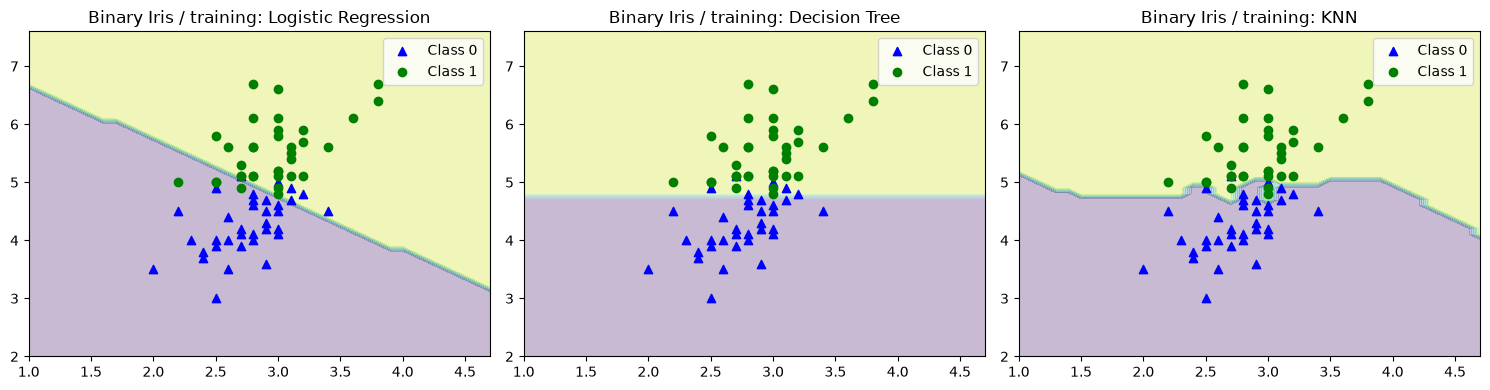

In [3]:
#Step 1.4: Training Individual Classifiers and Evaluating Performance

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
import matplotlib.pyplot as plt

# Create individual classifiers
clf1 = LogisticRegression(C=0.001, random_state=1)
clf2 = DecisionTreeClassifier(max_depth=1, criterion='entropy', random_state=0)
clf3 = KNeighborsClassifier(n_neighbors=1, p=2, metric='minkowski')

# Create pipelines
pipe1 = Pipeline([['sc', StandardScaler()], ['clf', clf1]])
pipe3 = Pipeline([['sc', StandardScaler()], ['clf', clf3]])

clf_labels = ['Logistic Regression', 'Decision Tree', 'KNN']

binary_folds = list(StratifiedKFold(10, shuffle=True, random_state=1).split(X_train, y_train))
binary_results = []
print('Binary Iris (versicolor/virginica), training-only 10-fold ROC-AUC:')
for clf, label in zip([pipe1, clf2, pipe3], clf_labels):
    scores = cross_val_score(estimator=clf, X=X_train, y=y_train, cv=binary_folds, scoring='roc_auc', error_score='raise')
    binary_results.append({'model': label, 'cv_auc_mean': float(scores.mean()), 'cv_auc_std': float(scores.std())})
    print("ROC AUC: %0.2f (+/- %0.2f) [%s]" % (scores.mean(), scores.std(), label))

# Visualization: Decision Boundaries for the 3 classifiers
def plot_classifier_boundary(clf, title):
    clf.fit(X_train, y_train)
    x_min, x_max = X_train[:,0].min()-1, X_train[:,0].max()+1
    y_min, y_max = X_train[:,1].min()-1, X_train[:,1].max()+1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                         np.arange(y_min, y_max, 0.1))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X_train[y_train==0,0], X_train[y_train==0,1], c='blue', marker='^', label='Class 0')
    plt.scatter(X_train[y_train==1,0], X_train[y_train==1,1], c='green', marker='o', label='Class 1')
    plt.title(title)
    plt.legend()

plt.figure(figsize=(15,4))
for i, (clf, label) in enumerate(zip([pipe1, clf2, pipe3], clf_labels)):
    plt.subplot(1,3,i+1)
    plot_classifier_boundary(clf, 'Binary Iris / training: ' + label)
plt.tight_layout()
plt.show()


Majority Voting Classifier - ROC AUC: 0.97 (+/- 0.04)


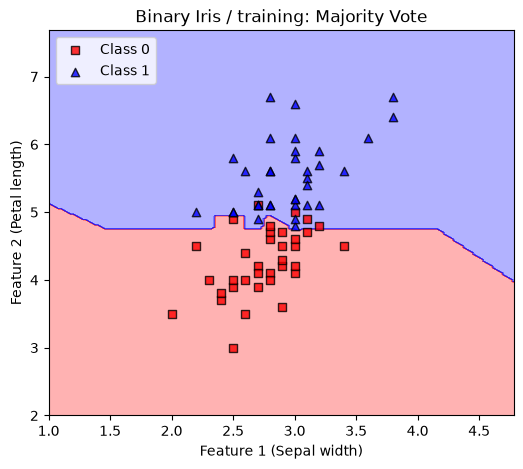

In [4]:
# Step 1.5: Train and Evaluate Majority Voting Classifier
# -------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import cross_val_score


# Create Majority Voting Classifier
mv_clf = MajorityVoteClassifier(classifiers=[pipe1, clf2, pipe3])

# Cross-validation evaluation
scores = cross_val_score(estimator=mv_clf, X=X_train, y=y_train, cv=binary_folds, scoring='roc_auc', error_score='raise')
print("\nMajority Voting Classifier - ROC AUC: %.2f (+/- %.2f)" % (scores.mean(), scores.std()))

# --- Visualization: Decision Boundary ---
def plot_decision_regions(X, y, classifier, title, resolution=0.02):
    # setup marker generator and color map
    markers = ('s', '^', 'o', 'v', 'D')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot decision surface
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = classifier.fit(X_train, y_train).predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # plot class samples
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0], y=X[y == cl, 1],
                    alpha=0.8, c=colors[idx],
                    marker=markers[idx], label=f"Class {cl}", edgecolor='black')

    plt.title(title)
    plt.xlabel("Feature 1 (Sepal width)")
    plt.ylabel("Feature 2 (Petal length)")
    plt.legend(loc='upper left')

# Plot decision boundary for Majority Voting
plt.figure(figsize=(6, 5))
plot_decision_regions(X_train, y_train, classifier=mv_clf, title="Binary Iris / training: Majority Vote")
plt.show()

binary_results.append({'model': 'Majority Vote', 'cv_auc_mean': float(scores.mean()), 'cv_auc_std': float(scores.std())})

Training set size: (95, 2)
Test set size: (24, 2)
Class distribution in y: {0: 71, 1: 48}


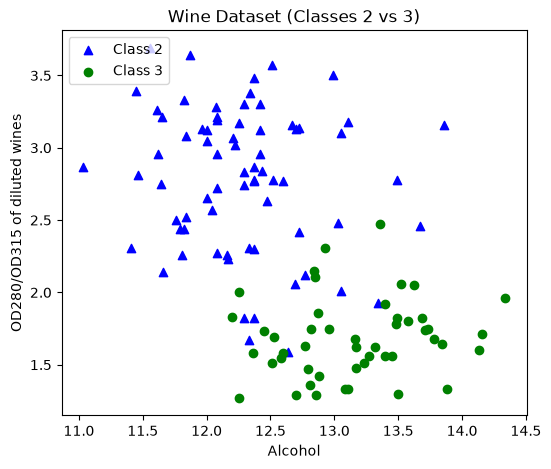

In [5]:
# Loading wine dataset and splitting into training and test sets

# Step 2.2: Prepare the Wine Dataset
# ----------------------------------
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.datasets import load_wine
wine = load_wine()
df_wine = pd.DataFrame(np.column_stack((wine.target + 1, wine.data)))

# Add column names
df_wine.columns = [
    'Class label', 'Alcohol', 'Malic acid', 'Ash', 'Alcalinity of ash',
    'Magnesium', 'Total phenols', 'Flavanoids', 'Nonflavanoid phenols',
    'Proanthocyanins', 'Color intensity', 'Hue',
    'OD280/OD315 of diluted wines', 'Proline'
]

# Keep only classes 2 and 3 (binary classification problem)
df_wine = df_wine[df_wine['Class label'] != 1]

# Define features (2D for visualization later) and target
X = df_wine[['Alcohol', 'OD280/OD315 of diluted wines']].values
y = df_wine['Class label'].values

# Encode class labels as 0 and 1
le = LabelEncoder()
y = le.fit_transform(y)

# Split dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

# Quick check of dataset shapes
print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)
print("Class distribution in y:", pd.Series(y).value_counts().to_dict())

# Visualization of dataset (scatter plot)
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color='blue', marker='^', label='Class 2')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='green', marker='o', label='Class 3')
plt.xlabel("Alcohol")
plt.ylabel("OD280/OD315 of diluted wines")
plt.title("Wine Dataset (Classes 2 vs 3)")
plt.legend(loc='upper left')
plt.show()

Decision Tree train/test accuracy: 1.000/0.833
Bagging train/test accuracy: 1.000/0.917


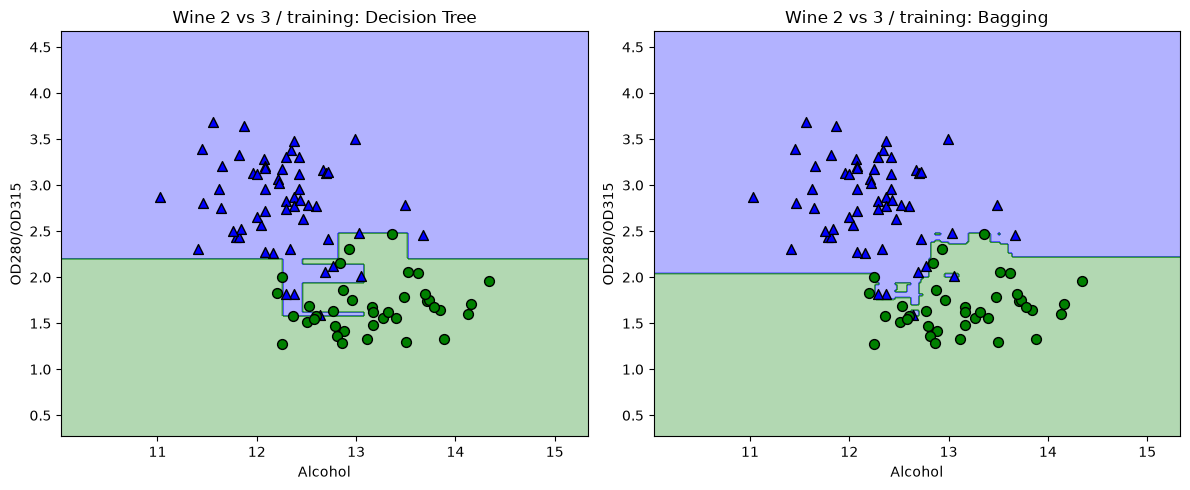

In [6]:
# Step 2.3: Bagging with Decision Trees
# -------------------------------------
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Base decision tree (weak learner)
tree = DecisionTreeClassifier(criterion='entropy', 
                              max_depth=None, 
                              random_state=1)

bag = BaggingClassifier(
    estimator=tree,
    n_estimators=500,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    n_jobs=1,     # bounded, reproducible resource use
    random_state=1
)

# Fit models
tree.fit(X_train, y_train)
bag.fit(X_train, y_train)

# Predictions
y_train_pred_tree = tree.predict(X_train)
y_test_pred_tree = tree.predict(X_test)

y_train_pred_bag = bag.predict(X_train)
y_test_pred_bag = bag.predict(X_test)

# Accuracies
tree_train_acc = accuracy_score(y_train, y_train_pred_tree)
tree_test_acc = accuracy_score(y_test, y_test_pred_tree)

bag_train_acc = accuracy_score(y_train, y_train_pred_bag)
bag_test_acc = accuracy_score(y_test, y_test_pred_bag)

print(f"Decision Tree train/test accuracy: {tree_train_acc:.3f}/{tree_test_acc:.3f}")
print(f"Bagging train/test accuracy: {bag_train_acc:.3f}/{bag_test_acc:.3f}")

# ------------------------------------
# Visualization: Decision boundaries
# ------------------------------------
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

fig, axarr = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# Plot decision surfaces for both models
for idx, clf, tt in zip([0, 1],
                        [tree, bag],
                        ['Wine 2 vs 3 / training: Decision Tree', 'Wine 2 vs 3 / training: Bagging']):
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    axarr[idx].contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(('blue', 'green')))
    axarr[idx].scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1],
                       c='blue', marker='^', edgecolor='k', s=50, label='Class 2')
    axarr[idx].scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1],
                       c='green', marker='o', edgecolor='k', s=50, label='Class 3')
    axarr[idx].set_title(tt)
    axarr[idx].set_xlabel("Alcohol")
    axarr[idx].set_ylabel("OD280/OD315")

plt.tight_layout()
plt.show()

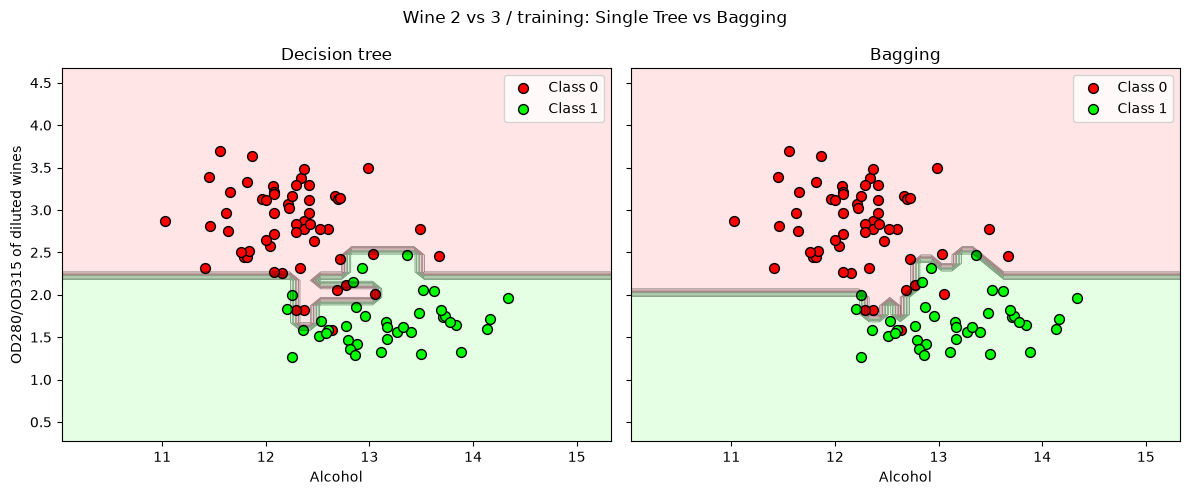

In [7]:
#Step 2.4: Visualizing Decision Boundaries

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

# Create mesh grid for plotting
x_min = X_train[:, 0].min() - 1
x_max = X_train[:, 0].max() + 1
y_min = X_train[:, 1].min() - 1
y_max = X_train[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

f, axarr = plt.subplots(nrows=1, ncols=2, sharex='col', sharey='row', figsize=(12, 5))

# Define colormap
cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA'])
cmap_bold = ListedColormap(['#FF0000', '#00FF00'])

for idx, clf, tt in zip([0, 1], [tree, bag], ['Decision tree', 'Bagging']):
    clf.fit(X_train, y_train)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    axarr[idx].contourf(xx, yy, Z, alpha=0.3, cmap=cmap_light)
    axarr[idx].contour(xx, yy, Z, colors='k', linewidths=0.5, alpha=0.5)
    
    # Plot training points
    for class_value in np.unique(y_train):
        class_mask = (y_train == class_value)
        axarr[idx].scatter(X_train[class_mask, 0], X_train[class_mask, 1], 
                          color=cmap_bold(class_value), label=f'Class {class_value}', 
                          edgecolor='k', s=50)
    
    axarr[idx].set_title(tt)
    axarr[idx].set_xlabel('Alcohol')
    if idx == 0:
        axarr[idx].set_ylabel('OD280/OD315 of diluted wines')
    axarr[idx].legend()

plt.suptitle('Wine 2 vs 3 / training: Single Tree vs Bagging')
plt.tight_layout()
plt.show()

Decision tree stump train/test accuracies 0.916/0.875


AdaBoost train/test accuracies 0.968/0.917


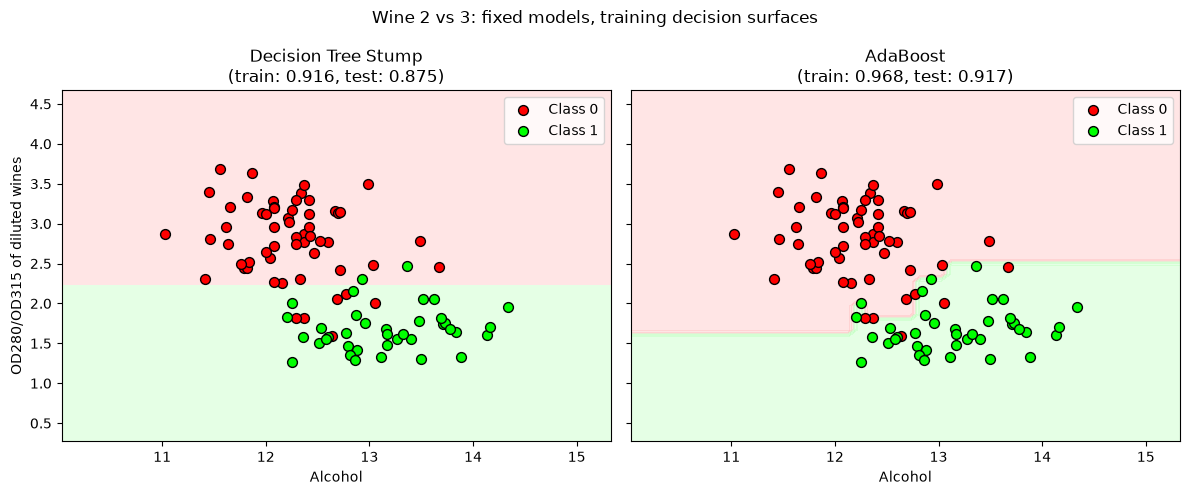

In [8]:
#PART 3: Implementing AdaBoost Classifier

#Step 3.2: Implement AdaBoost Classifier

from sklearn.ensemble import AdaBoostClassifier

# Create decision tree stump
tree_stump = DecisionTreeClassifier(criterion='entropy', 
                                    random_state=1, 
                                    max_depth=1)

# Create AdaBoost classifier
ada = AdaBoostClassifier(estimator=tree_stump,
                         n_estimators=500, 
                         learning_rate=0.1, 
                         random_state=1)

# Train individual decision tree stump
tree_stump = tree_stump.fit(X_train, y_train)
y_train_pred = tree_stump.predict(X_train)
y_test_pred = tree_stump.predict(X_test)
tree_train = accuracy_score(y_train, y_train_pred)
tree_test = accuracy_score(y_test, y_test_pred)
print('Decision tree stump train/test accuracies %.3f/%.3f' % (tree_train, tree_test))

# Train AdaBoost classifier
ada = ada.fit(X_train, y_train)
y_train_pred = ada.predict(X_train)
y_test_pred = ada.predict(X_test)
ada_train = accuracy_score(y_train, y_train_pred) 
ada_test = accuracy_score(y_test, y_test_pred)
print('AdaBoost train/test accuracies %.3f/%.3f' % (ada_train, ada_test))

# Create visualization for decision boundaries
fig, axes = plt.subplots(nrows=1, ncols=2, 
                         sharex='col', 
                         sharey='row', 
                         figsize=(12, 5))

# Plot decision tree stump
Z_stump = tree_stump.predict(np.c_[xx.ravel(), yy.ravel()])
Z_stump = Z_stump.reshape(xx.shape)
axes[0].contourf(xx, yy, Z_stump, alpha=0.3, cmap=cmap_light)
for class_val in np.unique(y_train):
    class_mask = (y_train == class_val)
    axes[0].scatter(X_train[class_mask, 0], 
                   X_train[class_mask, 1],
                   color=cmap_bold(class_val), 
                   label='Class %d' % class_val,
                   edgecolor='k', 
                   s=50)
axes[0].set_title('Decision Tree Stump\n(train: %.3f, test: %.3f)' % (tree_train, tree_test))
axes[0].set_xlabel('Alcohol')
axes[0].set_ylabel('OD280/OD315 of diluted wines')
axes[0].legend()

# Plot AdaBoost
Z_ada = ada.predict(np.c_[xx.ravel(), yy.ravel()])
Z_ada = Z_ada.reshape(xx.shape)
axes[1].contourf(xx, yy, Z_ada, alpha=0.3, cmap=cmap_light)
for class_val in np.unique(y_train):
    class_mask = (y_train == class_val)
    axes[1].scatter(X_train[class_mask, 0], 
                   X_train[class_mask, 1],
                   color=cmap_bold(class_val), 
                   label='Class %d' % class_val,
                   edgecolor='k', 
                   s=50)
axes[1].set_title('AdaBoost\n(train: %.3f, test: %.3f)' % (ada_train, ada_test))
axes[1].set_xlabel('Alcohol')
axes[1].legend()

fig.suptitle('Wine 2 vs 3: fixed models, training decision surfaces')
plt.tight_layout()
plt.show()

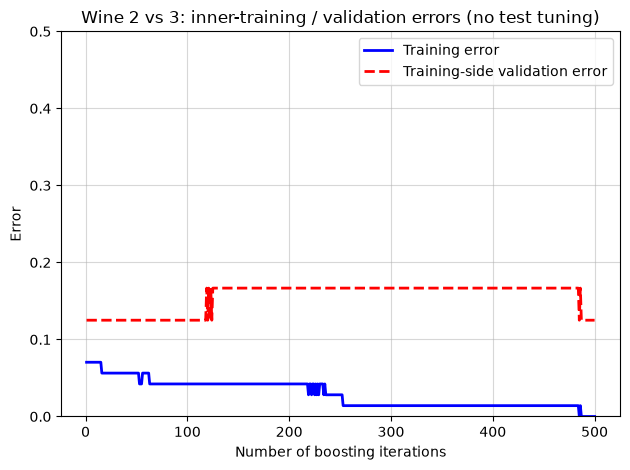

Minimum inner-validation error: 0.125 at iteration 1


In [9]:
#Step 3.3: Enhanced Error Convergence Analysis with Multiple Learning Rates

# Plot error convergence for AdaBoost
ada_conv = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, 
                                                              criterion='entropy',
                                                              random_state=1),
                             n_estimators=500, 
                             learning_rate=0.1, 
                             random_state=1)

X_inner, X_validation, y_inner, y_validation = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=1)
ada_conv.fit(X_inner, y_inner)
ada_train_err = []
ada_validation_err = []

for y_train_pred, y_test_pred in zip(ada_conv.staged_predict(X_inner), 
                                    ada_conv.staged_predict(X_validation)):
    ada_train_err.append(1 - accuracy_score(y_inner, y_train_pred))
    ada_validation_err.append(1 - accuracy_score(y_validation, y_test_pred))

plt.plot(range(1, len(ada_train_err) + 1), 
         ada_train_err, 
         label='Training error',
         color='blue', 
         linestyle='-',
         linewidth=2)

plt.plot(range(1, len(ada_validation_err) + 1), 
         ada_validation_err, 
         label='Training-side validation error',
         color='red', 
         linestyle='--',
         linewidth=2)

plt.xlabel('Number of boosting iterations')
plt.ylabel('Error')
plt.legend(loc='upper right')
plt.ylim(0, 0.5)
plt.grid(alpha=0.5)
plt.title('Wine 2 vs 3: inner-training / validation errors (no test tuning)')
plt.tight_layout()
plt.show()

# Exploratory validation minimum; final test labels are not inspected
min_validation_error_idx = np.argmin(ada_validation_err)
min_validation_error = ada_validation_err[min_validation_error_idx]
print('Minimum inner-validation error: %.3f at iteration %d' % (min_validation_error, min_validation_error_idx + 1))

In [10]:
#Step 4.1: Comprehensive Comparison

from sklearn.ensemble import RandomForestClassifier, VotingClassifier

# Prepare Iris dataset for comprehensive comparison
iris_full = datasets.load_iris()
X_full, y_full = iris_full.data, iris_full.target
X_train_full, X_test_full, y_train_full, y_test_full =\
       train_test_split(X_full, y_full,
                        test_size=0.3,
                        random_state=1,
                        stratify=y_full)

# Create individual classifiers
clf_lr = make_pipeline(StandardScaler(), LogisticRegression(random_state=1, max_iter=1000))
clf_knn = make_pipeline(StandardScaler(), KNeighborsClassifier())
clf_dt = DecisionTreeClassifier(random_state=1)
clf_rf = RandomForestClassifier(random_state=1)

# Create ensemble methods
voting_clf = VotingClassifier(estimators=[
    ('lr', clf_lr), ('knn', clf_knn), ('dt', clf_dt), ('rf', clf_rf)], 
    voting='hard')

bagging_clf = BaggingClassifier(estimator=clf_dt,
                               n_estimators=100,
                               random_state=1)

adaboost_clf = AdaBoostClassifier(estimator=clf_dt,
                                 n_estimators=100,
                                 random_state=1)

classifiers = [clf_lr, clf_knn, clf_dt, clf_rf, voting_clf, bagging_clf, adaboost_clf]
classifier_names = ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 
                    'Voting Classifier', 'Bagging', 'AdaBoost']

mv_full = MajorityVoteClassifier([clf_lr, clf_knn, clf_dt])
classifiers.append(mv_full)
classifier_names.append('Majority Vote')
full_folds = list(StratifiedKFold(10, shuffle=True, random_state=1).split(X_train_full, y_train_full))
# Evaluate every method on identical training folds with accuracy
results = []
for clf, name in zip(classifiers, classifier_names):
    scores = cross_val_score(clf, 
                            X_train_full, 
                            y_train_full, 
                            cv=full_folds, 
                            scoring='accuracy', error_score='raise')
    results.append({
        'Classifier': name,
        'Mean Accuracy': scores.mean(),
        'Std Accuracy': scores.std()
    })

results_df = pd.DataFrame(results)
print('\nFull Iris (all 4 features): training-only 10-fold accuracy:')
print('=' * 50)
print(results_df.sort_values('Mean Accuracy', ascending=False))


Full Iris (all 4 features): training-only 10-fold accuracy:
            Classifier  Mean Accuracy  Std Accuracy
6             AdaBoost       0.953636      0.061718
3        Random Forest       0.943636      0.084188
4    Voting Classifier       0.943636      0.084188
2        Decision Tree       0.943636      0.061496
5              Bagging       0.943636      0.084188
7        Majority Vote       0.943636      0.084188
1                  KNN       0.942727      0.076499
0  Logistic Regression       0.933636      0.094129


AdaBoost Best parameters:  {'learning_rate': 0.1, 'n_estimators': 50}
AdaBoost Best score: 0.971


Bagging Best parameters:  {'max_features': 0.8, 'max_samples': 0.5, 'n_estimators': 200}
Bagging Best score: 0.952


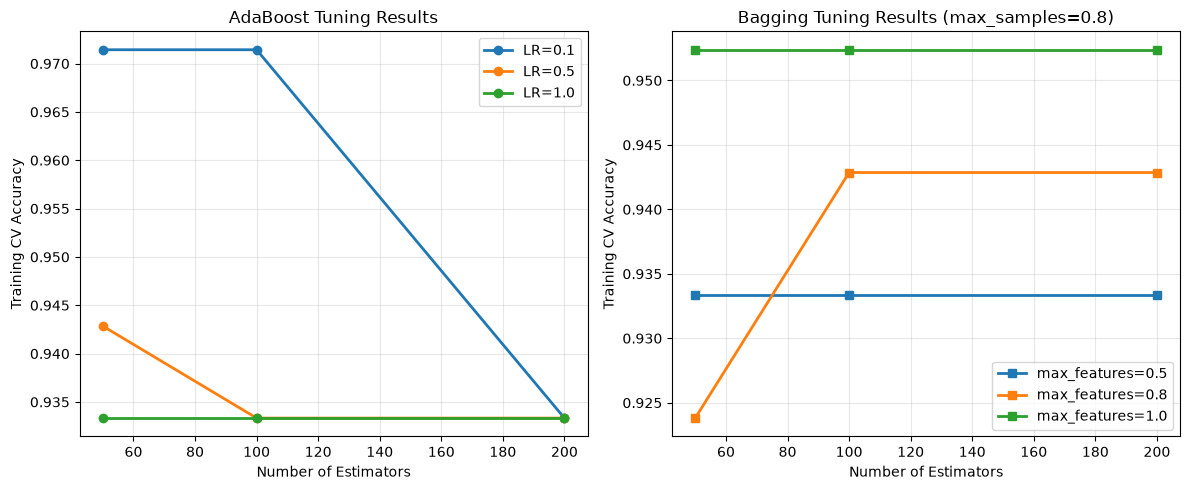


Full Iris: final held-out test performance:
AdaBoost (tuned) Test Accuracy: 0.978
Bagging (tuned) Test Accuracy: 0.978
Decision Tree (baseline) Test Accuracy: 0.978


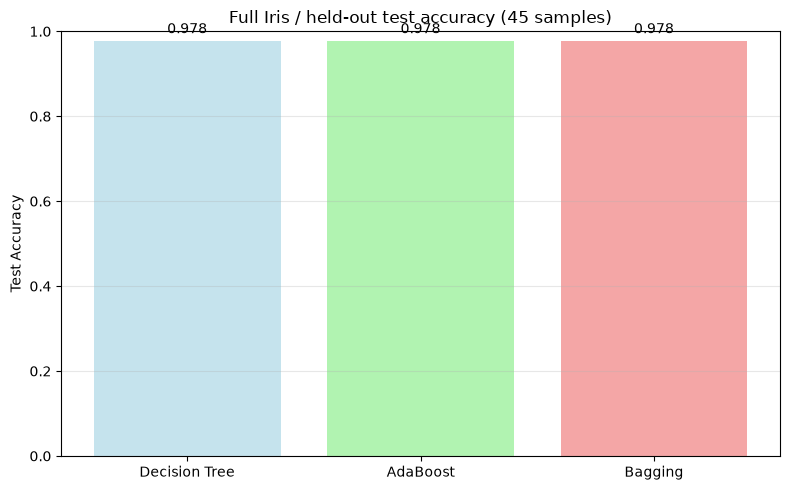


Improvement over Decision Tree:
AdaBoost relative change: +0.0%
Bagging relative change: +0.0%


In [11]:
#Step 4.2: Hyperparameter Tuning and Visualization

from sklearn.model_selection import GridSearchCV

# Tune AdaBoost parameters
param_grid_ada = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.1, 0.5, 1.0]
}

ada_base = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1,
                                                              random_state=1),
                             random_state=1)

gs_ada = GridSearchCV(estimator=ada_base,
                      param_grid=param_grid_ada,
                      cv=5,
                      scoring='accuracy',
                      n_jobs=1)

gs_ada.fit(X_train_full, y_train_full)

print("AdaBoost Best parameters: ", gs_ada.best_params_)
print("AdaBoost Best score: %.3f" % gs_ada.best_score_)

# Tune Bagging parameters
param_grid_bag = {
    'n_estimators': [50, 100, 200],
    'max_samples': [0.5, 0.8, 1.0],
    'max_features': [0.5, 0.8, 1.0]
}

bag_base = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1),
                            random_state=1)

gs_bag = GridSearchCV(estimator=bag_base,
                      param_grid=param_grid_bag,
                      cv=5,
                      scoring='accuracy',
                      n_jobs=1)

gs_bag.fit(X_train_full, y_train_full)

print("Bagging Best parameters: ", gs_bag.best_params_)
print("Bagging Best score: %.3f" % gs_bag.best_score_)

# Compare tuned models
tuned_models = {
    'AdaBoost (tuned)': gs_ada.best_estimator_,
    'Bagging (tuned)': gs_bag.best_estimator_
}

# best_score_ is selection CV, not an independent estimate after tuning.

# Simple visualization of tuning results
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

# AdaBoost results
ada_results = pd.DataFrame(gs_ada.cv_results_)
for lr in [0.1, 0.5, 1.0]:
    lr_mask = ada_results['param_learning_rate'] == lr
    axes[0].plot(ada_results[lr_mask]['param_n_estimators'],
                ada_results[lr_mask]['mean_test_score'],
                marker='o',
                label='LR=%.1f' % lr,
                linewidth=2)

axes[0].set_xlabel('Number of Estimators')
axes[0].set_ylabel('Training CV Accuracy')
axes[0].set_title('AdaBoost Tuning Results')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Bagging results (show for fixed max_samples=0.8)
bag_results = pd.DataFrame(gs_bag.cv_results_)
sample_mask = bag_results['param_max_samples'] == 0.8
feature_values = sorted(bag_results[sample_mask]['param_max_features'].unique())

for feature_val in feature_values:
    feature_mask = sample_mask & (bag_results['param_max_features'] == feature_val)
    axes[1].plot(bag_results[feature_mask]['param_n_estimators'],
                bag_results[feature_mask]['mean_test_score'],
                marker='s',
                label='max_features=%.1f' % feature_val,
                linewidth=2)

axes[1].set_xlabel('Number of Estimators')
axes[1].set_ylabel('Training CV Accuracy')
axes[1].set_title('Bagging Tuning Results (max_samples=0.8)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Final test set evaluation
best_ada = gs_ada.best_estimator_
best_bag = gs_bag.best_estimator_

best_ada.fit(X_train_full, y_train_full)
best_bag.fit(X_train_full, y_train_full)

y_pred_ada = best_ada.predict(X_test_full)
y_pred_bag = best_bag.predict(X_test_full)

ada_test_acc = accuracy_score(y_test_full, y_pred_ada)
bag_test_acc = accuracy_score(y_test_full, y_pred_bag)

print('\nFull Iris: final held-out test performance:')
print('=' * 40)
print("AdaBoost (tuned) Test Accuracy: %.3f" % ada_test_acc)
print("Bagging (tuned) Test Accuracy: %.3f" % bag_test_acc)

# Compare with baseline decision tree
baseline_dt = DecisionTreeClassifier(random_state=1)
baseline_dt.fit(X_train_full, y_train_full)
y_pred_dt = baseline_dt.predict(X_test_full)
dt_test_acc = accuracy_score(y_test_full, y_pred_dt)

print("Decision Tree (baseline) Test Accuracy: %.3f" % dt_test_acc)

# Simple bar chart comparison
models = ['Decision Tree', 'AdaBoost', 'Bagging']
accuracies = [dt_test_acc, ada_test_acc, bag_test_acc]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies, color=['lightblue', 'lightgreen', 'lightcoral'], alpha=0.7)

plt.ylabel('Test Accuracy')
plt.title('Full Iris / held-out test accuracy (45 samples)')
plt.ylim(0, 1.0)

# Add value labels on bars
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             '%.3f' % acc, ha='center', va='bottom')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Improvement analysis
ada_improvement = ((ada_test_acc - dt_test_acc) / dt_test_acc) * 100
bag_improvement = ((bag_test_acc - dt_test_acc) / dt_test_acc) * 100

print('\nImprovement over Decision Tree:')
print('=' * 40)
print("AdaBoost relative change: %+.1f%%" % ada_improvement)
print("Bagging relative change: %+.1f%%" % bag_improvement)

## Separate experiment records
Binary Iris AUC is not comparable to multiclass Iris accuracy. Wine has its own
classes, features and split. The following Wine comparison uses identical five
training folds for each fixed model. Fold standard deviations are descriptive,
not confidence intervals. Grid-search best scores above are model-selection
scores; the final Iris test evaluation remains separate. No universal ensemble
improvement, optimal estimator count or stopping iteration is established.

In [12]:
import json
from pathlib import Path

wine_folds = list(StratifiedKFold(5, shuffle=True, random_state=1).split(X_train, y_train))
wine_results = []
for name, estimator in [('Decision Tree', tree), ('Bagging (500)', bag),
                        ('Decision Stump', tree_stump), ('AdaBoost (500, lr=0.1)', ada)]:
    scores = cross_val_score(estimator, X_train, y_train, cv=wine_folds, scoring='accuracy', error_score='raise')
    estimator.fit(X_train, y_train)
    wine_results.append({'model': name, 'cv_accuracy_mean': float(scores.mean()),
                         'cv_accuracy_std': float(scores.std()),
                         'test_accuracy': float(accuracy_score(y_test, estimator.predict(X_test)))})
summary = {
    'seed': 1,
    'binary_iris': {'features': ['sepal width', 'petal length'], 'classes': ['versicolor', 'virginica'],
                    'train_samples': 70, 'test_samples': 30, 'folds': 10, 'metric': 'ROC-AUC', 'results': binary_results},
    'full_iris': {'features': iris_full.feature_names, 'train_samples': 105, 'test_samples': 45,
                  'folds': 10, 'metric': 'accuracy', 'results': results,
                  'tuning': {'adaboost_params': gs_ada.best_params_, 'bagging_params': gs_bag.best_params_,
                             'adaboost_selection_cv': float(gs_ada.best_score_), 'bagging_selection_cv': float(gs_bag.best_score_)},
                  'test_accuracy': {'Decision Tree': float(dt_test_acc), 'AdaBoost tuned': float(ada_test_acc), 'Bagging tuned': float(bag_test_acc)}},
    'binary_wine': {'features': ['alcohol', 'od280/od315_of_diluted_wines'], 'original_classes': [2, 3],
                    'train_samples': len(X_train), 'test_samples': len(X_test), 'folds': 5,
                    'metric': 'accuracy', 'results': wine_results},
}
Path('results.json').write_text(json.dumps(summary, indent=2) + '\n', encoding='utf-8')
print('Binary Wine: training-only CV and held-out accuracy')
print(pd.DataFrame(wine_results).to_string(index=False))

Binary Wine: training-only CV and held-out accuracy
                 model  cv_accuracy_mean  cv_accuracy_std  test_accuracy
         Decision Tree          0.821053         0.071393       0.833333
         Bagging (500)          0.873684         0.078772       0.916667
        Decision Stump          0.863158         0.042105       0.875000
AdaBoost (500, lr=0.1)          0.884211         0.077352       0.916667
